In [1]:
# Configure every external directory here before executing the notebook.
from pathlib import Path
import os

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
RAW_DIR = Path(os.environ.get("RIDESHARE_RAW_DIR", str(PROJECT_DIR / "data/raw/fhvhv")))
PROCESSED_DIR = Path(
    os.environ.get("RIDESHARE_PROCESSED_DIR", str(PROJECT_DIR / "data/processed"))
)
ZONE_DIR = Path(
    os.environ.get("RIDESHARE_ZONE_DIR", str(PROJECT_DIR / "data/reference/taxi_zones"))
)
WEATHER_DIR = Path(
    os.environ.get(
        "RIDESHARE_WEATHER_DIR", str(PROJECT_DIR / "data/reference/weather_hourly")
    )
)
ANALYSIS_DIR = PROJECT_DIR / "outputs/demand_analysis"
# Spark users: configure JAVA_HOME and, on Windows when required, HADOOP_HOME externally.

# All directories are configured here. Hide this cell to hide local paths.
from pathlib import Path

DATA_DIR = PROCESSED_DIR
REPAIR_DIR = DATA_DIR / "repair_2024_2025"
ZONE_DIR = ZONE_DIR
RESULTS_DIR = ANALYSIS_DIR
YEARS = [2021, 2022, 2023, 2024, 2025]
# Read validated repair candidates in place; never promote or overwrite originals.
USE_VALIDATED_REPAIRS = True
SAVE_FIGURES = True


# Spatial patterns in pickup demand

## Scope and interpretation

This analysis uses cleaned **pickup totals from January 2021 through December 2025**, across all recorded HVFHV platforms. It describes observed trip activity, not requests, vehicle supply, duration or a causal policy effect. All 60 monthly inputs must pass coverage checks before cross-year comparisons. Calendar-day exposure is used for normalized volume; missing inputs are never interpreted as zero demand. Local hour labels combine repeated daylight-saving hours.

All directories are configured in the first code cell. The map joins on LocationID and dissolves multipart zone records. Unmapped IDs remain in citywide totals and share denominators.


In [2]:
import calendar
import json
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
db = duckdb.connect()
db.execute("SET threads=1")
db.execute("SET memory_limit='256MB'")
db.execute("SET preserve_insertion_order=false")
plt.rcParams.update(
    {
        "figure.figsize": (12, 5),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 110,
    }
)


def finish(fig, name):
    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(RESULTS_DIR / (name + ".png"), dpi=180, bbox_inches="tight")
    plt.show()


In [3]:
NOTEBOOK_ID = "05_spatial"
DIRECTIONS = ["pickup"]


In [4]:
# Check each monthly pickup table before including it in the analysis.
manifest, daily_frames, zone_frames, profile_frames = [], [], [], []
for year in YEARS:
    for month in range(1, 13):
        folder = DATA_DIR / f"fhvhv_by_zone_hour_{year}_{month:02d}.parquet"
        parts = sorted(folder.glob("*.parquet"))
        assert (
            parts and (folder / "_SUCCESS").exists()
        ), f"Incomplete input: {folder.name}"
        db.read_parquet([str(p) for p in parts]).create_view("source", replace=True)
        bad = db.execute(
            f"""SELECT count(*) FROM source WHERE
            PULocationID IS NULL OR date IS NULL OR hour IS NULL
            OR hour NOT BETWEEN 0 AND 23 OR trip_count IS NULL OR trip_count <= 0
            OR year(date) != {year} OR month(date) != {month}"""
        ).fetchone()[0]
        duplicates = db.execute(
            """SELECT count(*) FROM
            (SELECT 1 FROM source GROUP BY PULocationID, date, hour HAVING count(*) > 1)"""
        ).fetchone()[0]
        dates = db.execute("SELECT count(DISTINCT date) FROM source").fetchone()[0]
        assert bad == duplicates == 0, f"Invalid rows/keys: {folder.name}"
        assert (
            dates == calendar.monthrange(year, month)[1]
        ), f"Incomplete dates: {folder.name}"
        manifest.append(
            dict(
                direction="pickup",
                year=year,
                month=month,
                status="included",
                path=str(folder),
            )
        )
        queries = [
            (
                daily_frames,
                "SELECT date, sum(trip_count) trips FROM source GROUP BY date",
            ),
            (
                zone_frames,
                "SELECT PULocationID zone_id, sum(trip_count) trips FROM source GROUP BY PULocationID",
            ),
            (
                profile_frames,
                'SELECT dayofweek(date) dow, hour AS "hour", sum(trip_count) trips FROM source GROUP BY dayofweek(date), hour',
            ),
        ]
        for frames, sql in queries:
            frame = db.execute(sql).df()
            frame = frame.assign(direction="pickup", year=year, month=month)
            frames.append(frame)
manifest = pd.DataFrame(manifest)
assert len(manifest) == 60
daily = pd.concat(daily_frames, ignore_index=True)
daily["date"] = pd.to_datetime(daily.date)
zone_month = pd.concat(zone_frames, ignore_index=True)
profiles = pd.concat(profile_frames, ignore_index=True)
assert daily.date.between("2021-01-01", "2025-12-31").all()
manifest.to_csv(RESULTS_DIR / f"{NOTEBOOK_ID}_input_manifest.csv", index=False)
daily.to_csv(RESULTS_DIR / f"{NOTEBOOK_ID}_daily_totals.csv", index=False)
display(manifest.groupby("year").size().rename("complete_months"))


year
2021    12
2022    12
2023    12
2024    12
2025    12
Name: complete_months, dtype: int64

## Load the taxi-zone map
The join uses LocationID. Unmatched/unknown zones remain in total-demand tables, but cannot be mapped. Map values are trips/day, not trips per unit area.

In [5]:
import geopandas as gpd

shape_files = sorted(ZONE_DIR.glob("*.shp"))
assert len(shape_files) == 1, "Expected one zone shapefile in ZONE_DIR"
zones = gpd.read_file(shape_files[0])
assert "LocationID" in zones.columns, "Shapefile must contain LocationID"
zones["LocationID"] = pd.to_numeric(zones["LocationID"], errors="raise")
assert zones["LocationID"].notna().all(), "Missing zone identifiers in shapefile"
# Some taxi zones have separate polygon records. Union their geometry by ID.
attributes = [c for c in ["zone", "borough"] if c in zones.columns]
for column in attributes:
    assert (
        zones.groupby("LocationID")[column].nunique(dropna=False).le(1).all()
    ), f"Conflicting {column} labels within a zone"
polygon_records = len(zones)
zones = zones[["LocationID", *attributes, "geometry"]].dissolve(
    by="LocationID", as_index=False, aggfunc="first"
)
assert zones["LocationID"].is_unique
print(
    f"Merged {polygon_records} polygon records into {len(zones)} distinct mapped zones."
)
display(zones.drop(columns="geometry").head())
included = manifest[manifest.status == "included"]
common_months = sorted(
    set.intersection(*included.groupby(["direction", "year"]).month.apply(set).tolist())
)
print("Using common months for spatial year comparisons:", common_months)
z = (
    zone_month[zone_month.month.isin(common_months)]
    .groupby(["direction", "year", "zone_id"], as_index=False)
    .trips.sum()
)
days = (
    daily[daily.month.isin(common_months)]
    .groupby(["direction", "year"])
    .date.nunique()
    .rename("days")
    .reset_index()
)
z = z.merge(days, on=["direction", "year"])
z["trips_per_day"] = z.trips / z.days
z["share"] = z.trips / z.groupby(["direction", "year"]).trips.transform("sum")
unmapped = z[~z.zone_id.isin(zones.LocationID)]
display(
    unmapped.groupby(["direction", "year"])
    .trips.sum()
    .rename("unmapped_trips")
    .to_frame()
)
z.to_csv(RESULTS_DIR / "05_zone_demand.csv", index=False)


Merged 263 polygon records into 260 distinct mapped zones.


,LocationID,zone,borough
0,1,Newark Airport,EWR
1,2,Jamaica Bay,Queens
2,3,Allerton/Pelham Gardens,Bronx
3,4,Alphabet City,Manhattan
4,5,Arden Heights,Staten Island


Using common months for spatial year comparisons: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


unmapped_trips
direction year                
pickup    2021         49011.0
          2022         52455.0
          2023         60636.0
          2024         59694.0
          2025         69409.0

### Compare absolute pickup activity across years
Join zone IDs to dissolved geometry and use one volume scale across annual panels. Unmapped IDs remain in demand totals.


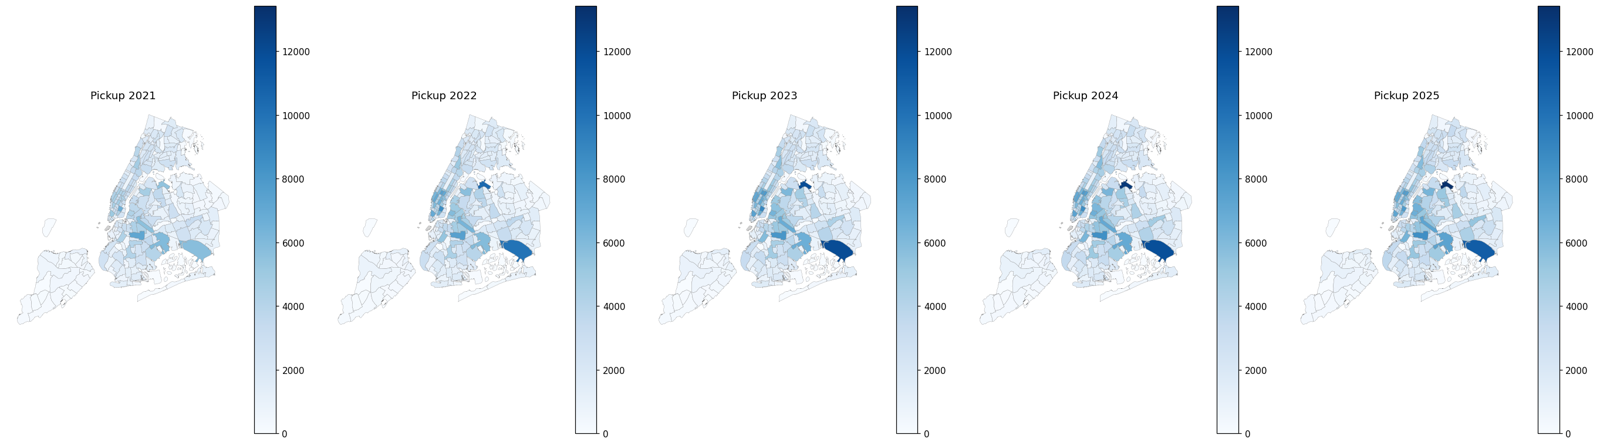

In [6]:
# Shared color scale across years within each direction.
years = sorted(z.year.unique())
for direction in DIRECTIONS:
    subset = z[z.direction == direction]
    vmax = subset.trips_per_day.max()
    fig, axes = plt.subplots(1, len(years), figsize=(5 * len(years), 7), squeeze=False)
    for ax, year in zip(axes.flat, years):
        layer = zones.merge(
            subset[subset.year == year],
            left_on="LocationID",
            right_on="zone_id",
            how="left",
        )
        layer.plot(
            column="trips_per_day",
            ax=ax,
            cmap="Blues",
            vmin=0,
            vmax=vmax,
            legend=True,
            missing_kwds={"color": "lightgrey", "label": "No observed row"},
            edgecolor="#808080",
            linewidth=0.2,
        )
        ax.set_title(f"{direction.title()} {year}")
        ax.set_axis_off()
    finish(fig, f"05_{direction}_zone_maps")


### Rank locations and measure concentration
Rank zones by average daily pickups, then use cumulative citywide shares to show how much demand is concentrated in the busiest locations.


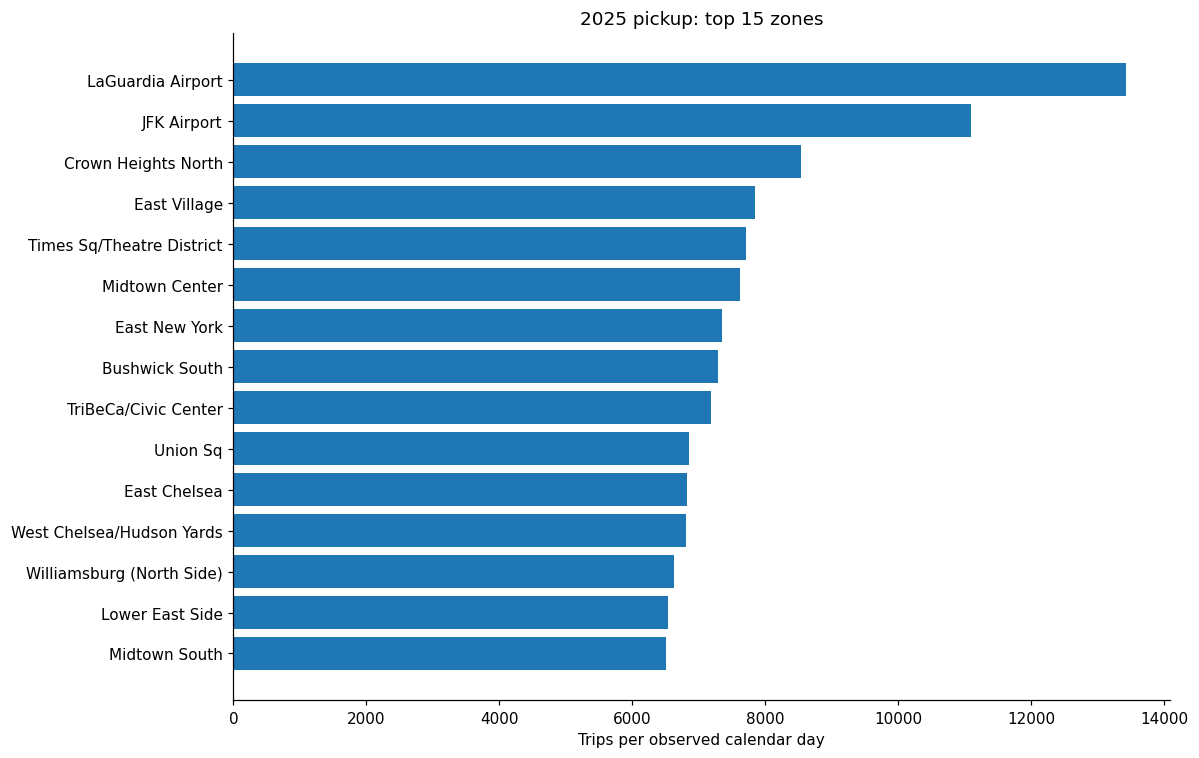

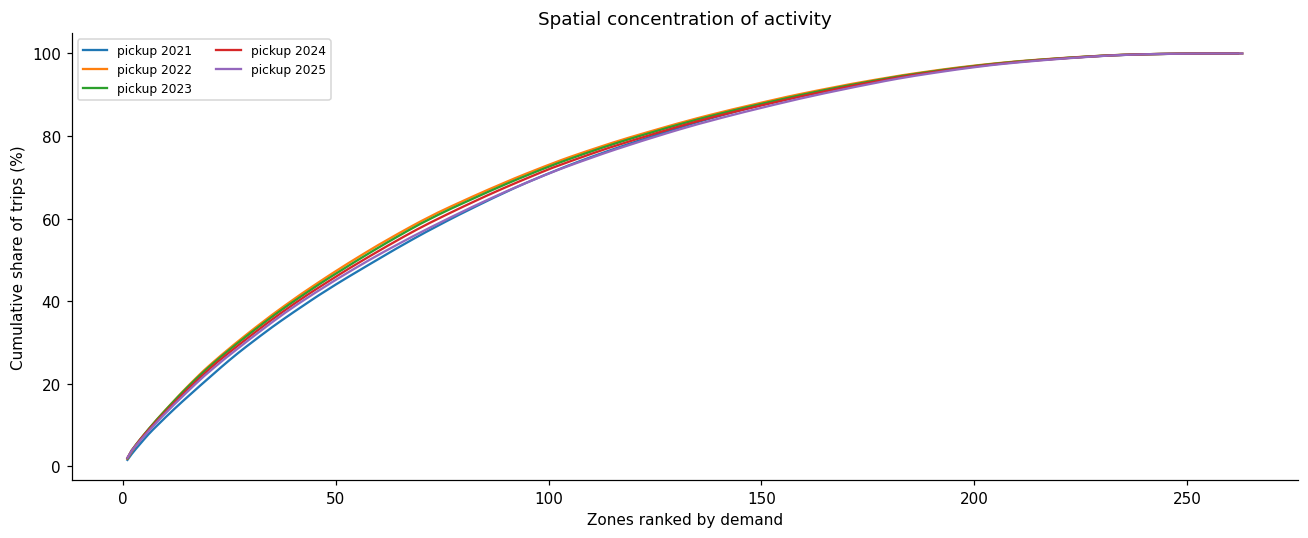

In [7]:
latest = int(z.year.max())
label_col = next((c for c in ["zone", "Zone", "NAME"] if c in zones.columns), None)
lookup = zones[["LocationID", label_col]] if label_col else zones[["LocationID"]]
ranked = z[z.year == latest].merge(
    lookup, left_on="zone_id", right_on="LocationID", how="left"
)
fig, axes = plt.subplots(1, 1, figsize=(11, 7))
axes = np.atleast_1d(axes)
for ax, direction in zip(axes, DIRECTIONS):
    top = (
        ranked[ranked.direction == direction]
        .nlargest(15, "trips_per_day")
        .sort_values("trips_per_day")
    )
    labels = (
        top[label_col].fillna(top.zone_id.astype(str))
        if label_col
        else top.zone_id.astype(str)
    )
    ax.barh(labels, top.trips_per_day)
    ax.set(
        title=f"{latest} {direction}: top 15 zones",
        xlabel="Trips per observed calendar day",
    )
finish(fig, "05_top_zones")
fig, ax = plt.subplots()
for (direction, year), g in z.groupby(["direction", "year"]):
    shares = g.share.sort_values(ascending=False).to_numpy()
    ax.plot(
        np.arange(1, len(shares) + 1),
        np.cumsum(shares) * 100,
        label=f"{direction} {year}",
    )
ax.set(
    title="Spatial concentration of activity",
    xlabel="Zones ranked by demand",
    ylabel="Cumulative share of trips (%)",
)
ax.legend(ncol=2, fontsize=8)
finish(fig, "05_demand_concentration")


### Compare two periods of spatial redistribution
The paired maps show changes in citywide pickup share for 2021–2024 and 2024–2025. The detail map uses a separate scale to resolve the smaller recent changes.


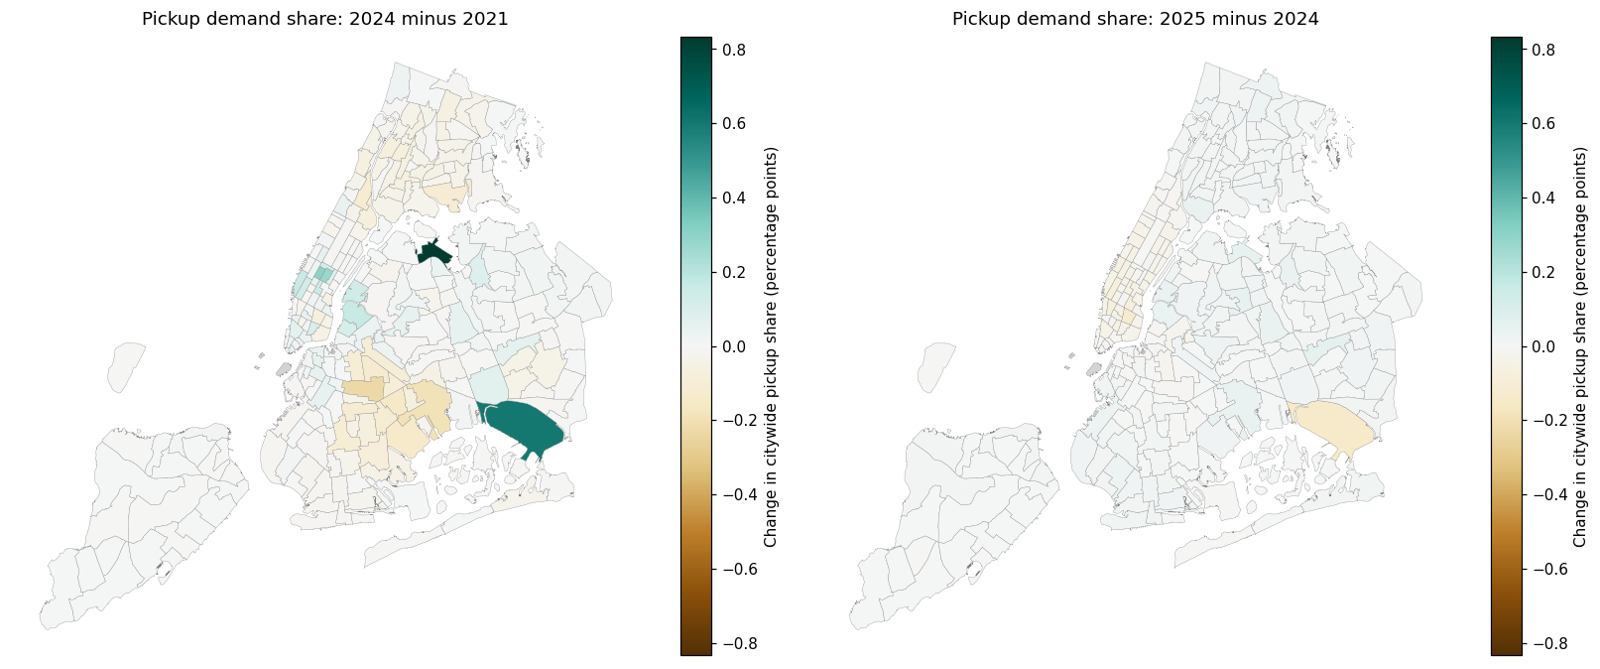

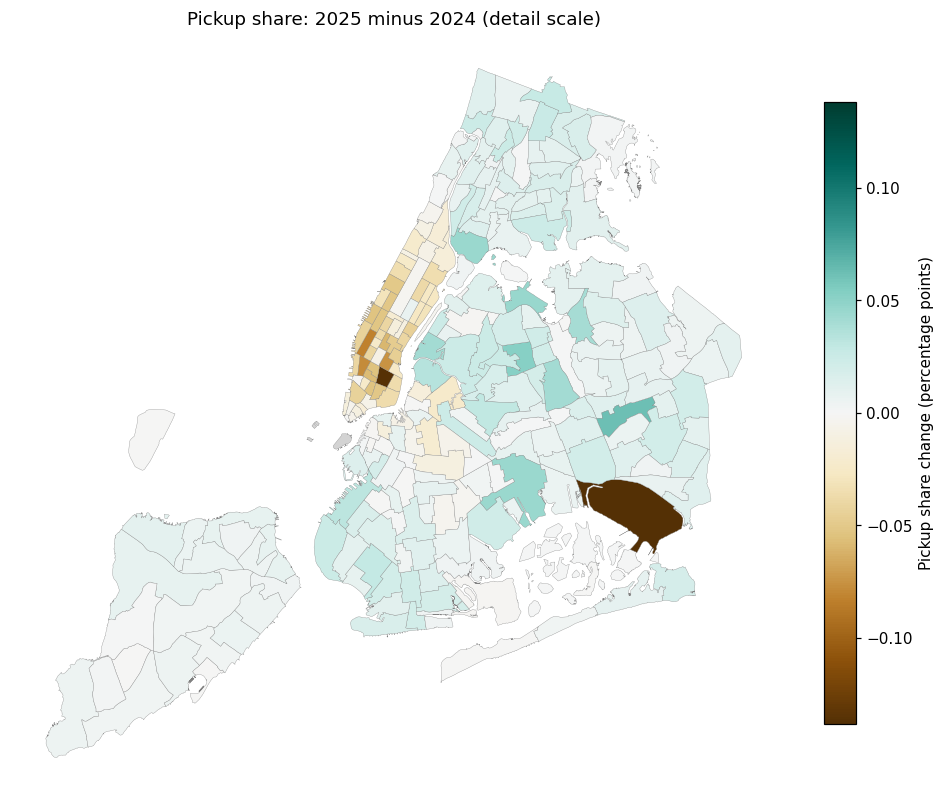

In [8]:
# Compare shares, not raw growth: differences are percentage points.
COMPARISONS = [(2021, 2024), (2024, 2025)]
shares = (
    z[z.direction.eq("pickup")]
    .pivot(index="zone_id", columns="year", values="share")
    .fillna(0)
)
changes = []
for first, last in COMPARISONS:
    change = (
        ((shares[last] - shares[first]) * 100).rename("share_change_pp").reset_index()
    )
    change = change.assign(first_year=first, last_year=last)
    assert abs(change.share_change_pp.sum()) < 1e-8
    changes.append(change)
bound = max(max(abs(c.share_change_pp)) for c in changes)
fig, axes = plt.subplots(1, 2, figsize=(15, 9))
for ax, change in zip(axes, changes):
    first, last = int(change.first_year.iloc[0]), int(change.last_year.iloc[0])
    layer = zones.merge(change, left_on="LocationID", right_on="zone_id", how="left")
    layer.plot(
        column="share_change_pp",
        ax=ax,
        cmap="BrBG",
        vmin=-bound,
        vmax=bound,
        legend=True,
        legend_kwds={
            "label": "Change in citywide pickup share (percentage points)",
            "shrink": 0.65,
        },
        missing_kwds={"color": "lightgrey"},
        edgecolor="#808080",
        linewidth=0.2,
    )
    ax.set_title(f"Pickup demand share: {last} minus {first}")
    ax.set_axis_off()
finish(fig, "05_pickup_share_comparisons")
share_changes = pd.concat(changes, ignore_index=True)
share_changes.to_csv(RESULTS_DIR / "05_pickup_share_comparisons.csv", index=False)

# A second view resolves the smaller 2024–2025 changes on its own scale.
# The paired figure above remains the comparison with a common scale.
recent = changes[-1]
recent_bound = max(abs(recent.share_change_pp))
layer = zones.merge(recent, left_on="LocationID", right_on="zone_id", how="left")
fig, ax = plt.subplots(figsize=(9, 9))
layer.plot(
    column="share_change_pp",
    ax=ax,
    cmap="BrBG",
    vmin=-recent_bound,
    vmax=recent_bound,
    legend=True,
    legend_kwds={"label": "Pickup share change (percentage points)", "shrink": 0.65},
    missing_kwds={"color": "lightgrey"},
    edgecolor="#808080",
    linewidth=0.2,
)
ax.set_title("Pickup share: 2025 minus 2024 (detail scale)")
ax.set_axis_off()
finish(fig, "05_pickup_share_change_2024_2025_detail")


## Findings to record

### Coverage and concentration
The spatial comparison uses all 12 months in each year from **2021–2025**. Shares use all observed pickup zones in the denominator, including unmapped IDs. The zone geometry is dissolved by LocationID before joining.

In 2025, the ten busiest pickup zones accounted for **12.90%** of citywide cleaned pickups. Unmapped IDs accounted for **0.029%**; they contribute to totals but cannot be colored on the map. Spatial activity is concentrated rather than evenly spread, and the common color scale distinguishes absolute increases from changes in relative demand.

### Leading pickup locations in 2025
| Zone | Borough | Daily pickups | Citywide share |
|---|---|---:|---:|
| LaGuardia Airport | Queens | 13,423 | 2.04% |
| JFK Airport | Queens | 11,095 | 1.69% |
| Crown Heights North | Brooklyn | 8,542 | 1.30% |
| East Village | Manhattan | 7,845 | 1.19% |
| Times Sq/Theatre District | Manhattan | 7,711 | 1.17% |

### Changes in pickup demand share
The two maps compare **2024 minus 2021** and **2025 minus 2024**, on a shared diverging scale. Positive values indicate an increase in a zone’s fraction of citywide pickups; units are **percentage points**, not percent growth. A zone can gain trips while losing share if citywide demand grows faster.

**2021–2024:** largest share gains were LaGuardia Airport (+0.832 pp), JFK Airport (+0.603 pp), Times Sq/Theatre District (+0.304 pp). Largest losses were Crown Heights North (-0.228 pp), East New York (-0.194 pp), Brownsville (-0.151 pp).

**2024–2025:** largest share gains were Jamaica (+0.062 pp), Elmhurst (+0.052 pp), LaGuardia Airport (+0.046 pp). Largest losses were JFK Airport (-0.138 pp), East Village (-0.136 pp), East Chelsea (-0.082 pp).

### Interpretation and limits
Maps show pickups per calendar day or pickup shares, not density per square kilometre, requests or vehicle availability. The long comparison describes spatial redistribution over several years; the 2024–2025 comparison describes a shorter change. Neither identifies a causal congestion-pricing effect. Boundary/geometry coverage and differences in zone area matter when interpreting the maps.
